In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from cwfc.validation import rolling_origin_splits
from cwfc.baselines import persistence_forecast
from cwfc.metrics import mae
from cwfc.metrics import rmse
from cwfc.metrics import smape

In [3]:
data = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
print(data.head())  

   timestamp                                              vm_id   min_cpu  \
0          0  H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...  1.812194   
1          0  pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...  4.126021   
2          0  iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...  1.225669   
3          0  /f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...  1.939634   
4          0  wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...  0.352236   

     max_cpu   avg_cpu  
0  14.587021  4.851659  
1   5.650850  4.687886  
2   2.082111  1.607588  
3   3.228830  2.374714  
4   0.855003  0.597535  


In [4]:
line_numbers = data.shape[0]
column_numbers = data.shape[1]
type_column = data.dtypes
null_columns = data.isnull().sum()
print(line_numbers)
print(column_numbers)
print(type_column)
print(null_columns)

1340000
5
timestamp      int64
vm_id            str
min_cpu      float64
max_cpu      float64
avg_cpu      float64
dtype: object
timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64


In [5]:
min = data.min()
max = data.max()
numbers_id = data.nunique()
dublicate = data.duplicated().any()
print(numbers_id)
print(dublicate)
print(min)
print(max)

timestamp        134
vm_id          10000
min_cpu      1339898
max_cpu      1340000
avg_cpu      1340000
dtype: int64
False
timestamp                                                    0
vm_id        ++HH65MmT9ktdMdfSKCLk9O/VFunMJLxKrbFC64hN4zKe5...
min_cpu                                                    0.0
max_cpu                                               0.018108
avg_cpu                                               0.007159
dtype: object
timestamp                                                39900
vm_id        zzoMlvf43P5P9u5ZC8tbXjKZv54e6JZ5GRkvOQtG2vzfPb...
min_cpu                                              99.281582
max_cpu                                               99.70286
avg_cpu                                              99.488027
dtype: object


In [6]:
describe = data.describe()
print(describe)

          timestamp       min_cpu       max_cpu       avg_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06  1.340000e+06
mean   1.995000e+04  6.156478e+00  1.834830e+01  9.388101e+00
std    1.160442e+04  1.175525e+01  2.161651e+01  1.426601e+01
min    0.000000e+00  0.000000e+00  1.810795e-02  7.158922e-03
25%    9.900000e+03  1.487979e+00  4.417642e+00  2.477060e+00
50%    1.995000e+04  3.227996e+00  9.124204e+00  5.105133e+00
75%    3.000000e+04  5.331087e+00  2.362418e+01  9.616715e+00
max    3.990000e+04  9.928158e+01  9.970286e+01  9.948803e+01


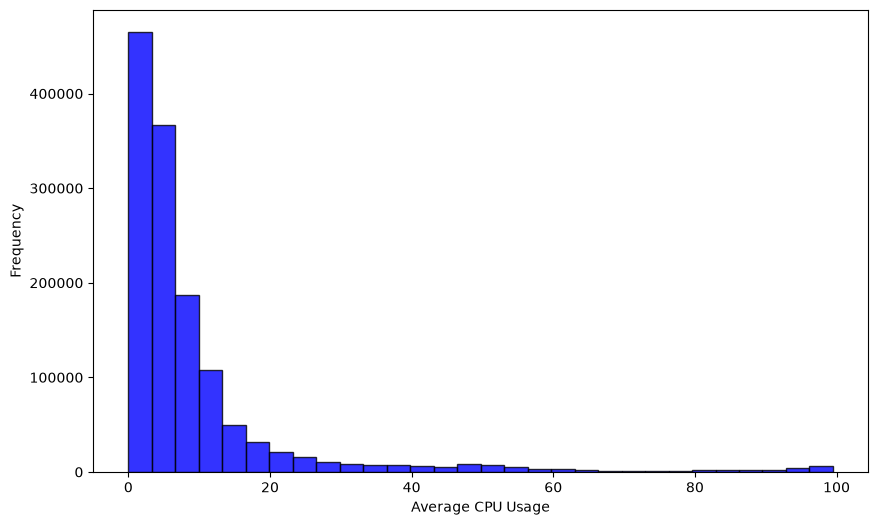

In [7]:
plt.figure(figsize=(10, 6))
plt.hist(data["avg_cpu"], bins=30, color="blue", edgecolor="black", alpha=0.8)
plt.xlabel("Average CPU Usage")
plt.ylabel("Frequency")
plt.show()

In [8]:
print(data["avg_cpu"].between(0, 100).all())
print(data["min_cpu"].between(0, 100).all())
print(data["max_cpu"].between(0, 100).all())

True
True
True


In [9]:
print((data["min_cpu"] <= data["avg_cpu"]).all())
print((data["avg_cpu"] <= data["max_cpu"]).all())

True
True


In [10]:
time = data.sort_values(by="timestamp", ascending=True)
print(time.head(5))
print(time.tail(5))

   timestamp                                              vm_id   min_cpu  \
0          0  H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...  1.812194   
1          0  pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...  4.126021   
2          0  iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...  1.225669   
3          0  /f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...  1.939634   
4          0  wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...  0.352236   

     max_cpu   avg_cpu  
0  14.587021  4.851659  
1   5.650850  4.687886  
2   2.082111  1.607588  
3   3.228830  2.374714  
4   0.855003  0.597535  
         timestamp                                              vm_id  \
1339995      39900  GI1NSfZ3RtVtCCax6F69SEYBZPDvGr3l05bneutjReACJv...   
1339996      39900  4sQlZ1VeuUk5zAdkNFjxaXEsI3ROLZtFzOMiuDleoQOmKn...   
1339997      39900  BytpDwExOQ93bgjfsVJxqQFepypm0VC99Z2m8s+OMyZSUN...   
1339998      39900  aDokW2s1f3+IYoSTWTIC7JtuEAQ7ACncN2BsZZO7E6506u...   
1339999      39900  aB

In [11]:
counts = data["timestamp"].value_counts()

print("Minimum count:", counts.min())
print("Maximum count:", counts.max())
print(counts.min() == counts.max())

Minimum count: 10000
Maximum count: 10000
True


In [12]:
timestamps = data["timestamp"].drop_duplicates().sort_values()

time_diff = timestamps.diff()

print(time_diff)
print(time_diff.dropna().eq(300).all())

0            NaN
10000      300.0
20000      300.0
30000      300.0
40000      300.0
           ...  
1290000    300.0
1300000    300.0
1310000    300.0
1320000    300.0
1330000    300.0
Name: timestamp, Length: 134, dtype: float64
True


In [13]:
time_counts = data["timestamp"].value_counts()
min_count = time_counts.min()
max_count = time_counts.max()
print(time_counts)
print(min_count)
print(max_count)

timestamp
0        10000
300      10000
600      10000
900      10000
1200     10000
         ...  
38700    10000
39000    10000
39300    10000
39600    10000
39900    10000
Name: count, Length: 134, dtype: int64
10000
10000


timestamp
0       9.396898
300     9.353775
600     9.454383
900     9.224419
1200    9.143503
Name: avg_cpu, dtype: float64


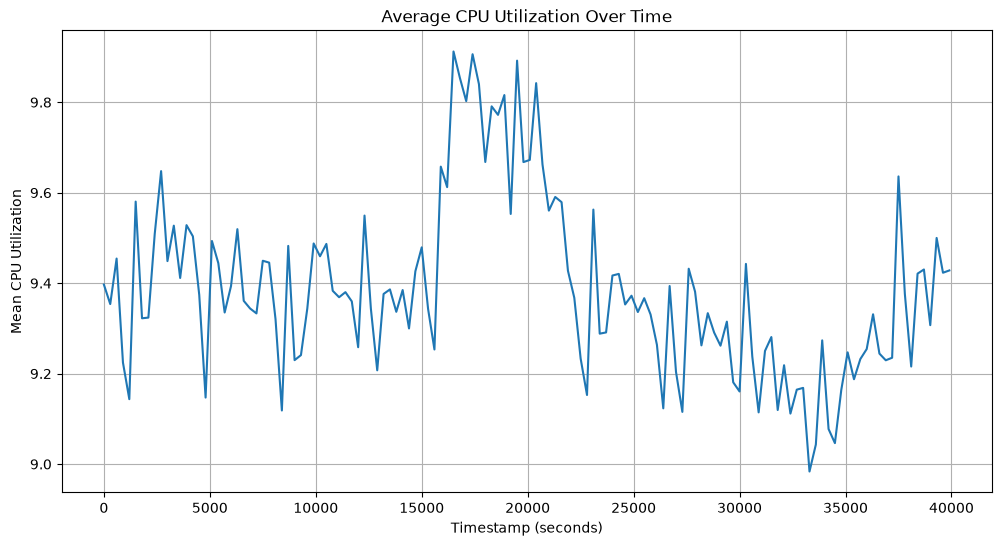

In [14]:
cpu_timeseries = data.groupby("timestamp")["avg_cpu"].mean()
cpu_timeseries = cpu_timeseries.sort_index()
print(cpu_timeseries.head())
cpu_timeseries.plot(figsize=(12, 6))
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Mean CPU Utilization")
plt.title("Average CPU Utilization Over Time")
plt.grid(True)
plt.show()

In [15]:
metadata = pd.read_csv("../challenge_data/vm_metadata.csv.gz")
number_lines_metadata = metadata.shape[0]
number_columns_metadata = metadata.shape[1]
metadata_type_column = metadata.dtypes
metadata_null_columns = metadata.isnull().sum()
print(metadata.head())

                                               vm_id  \
0  FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...   
1  BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...   
2  vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...   
3  88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...   
4  C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...   

                                     subscription_id  \
0  zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...   
1  JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...   
2  0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...   
3  4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...   
4  1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...   

                                       deployment_id  timestamp_vm_created  \
0  gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...                     0   
1  +qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...                     0   
2  TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...                     0   
3  yfPM2qpoqC9

In [16]:
print(number_lines_metadata)
print(number_columns_metadata)
print(metadata_type_column)
print(metadata_null_columns) 

10000
11
vm_id                       str
subscription_id             str
deployment_id               str
timestamp_vm_created      int64
timestamp_vm_deleted      int64
max_cpu                 float64
avg_cpu                 float64
p95_max_cpu             float64
vm_category                 str
virtual_core_bucket         str
memory_gb_bucket            str
dtype: object
vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64


In [17]:
numbers_vm_id = metadata["vm_id"].nunique()
print(numbers_vm_id)
cpu_ids = set(data["vm_id"])
metadata_ids = set(metadata["vm_id"])
print(cpu_ids.issubset(metadata_ids))
vm_id_counts = metadata["vm_id"].value_counts()
print(vm_id_counts.eq(1).all())

10000
True
True


In [18]:
groupby_time = data.groupby("timestamp")
unique_vm_id = groupby_time["vm_id"].nunique()
mean_avg_cpu = groupby_time["avg_cpu"].mean()
final_dataframe = pd.DataFrame({"active_vm_count": unique_vm_id, "aggregate_cpu_utilization": mean_avg_cpu})
final_dataframe = final_dataframe.reset_index()
print(final_dataframe.head())

   timestamp  active_vm_count  aggregate_cpu_utilization
0          0            10000                   9.396898
1        300            10000                   9.353775
2        600            10000                   9.454383
3        900            10000                   9.224419
4       1200            10000                   9.143503


In [19]:
check_lines = final_dataframe.shape[0]
is_null = final_dataframe[["timestamp", "active_vm_count", "aggregate_cpu_utilization"]].isnull().sum()
increasing_or_not = final_dataframe["timestamp"].is_monotonic_increasing
difference = final_dataframe["timestamp"].diff().dropna().eq(300).all()
print(check_lines)
print(is_null)
print(increasing_or_not)
print(difference)


134
timestamp                    0
active_vm_count              0
aggregate_cpu_utilization    0
dtype: int64
True
True


In [20]:
learning_dataframe = final_dataframe.head(110).copy()
test_dataframe = final_dataframe.iloc[110:].copy()
print(learning_dataframe.shape[0])
print(test_dataframe.shape[0])
print(learning_dataframe["timestamp"].iloc[0])
print(learning_dataframe["timestamp"].iloc[-1])
print(test_dataframe["timestamp"].iloc[0])
print(test_dataframe["timestamp"].iloc[-1])

110
24
0
32700
33000
39900


In [24]:
learning_dataframe.to_csv("../learning_dataframe.csv", index=False)
test_dataframe.to_csv("../test_dataframe.csv", index=False)

     timestamp  active_vm_count  aggregate_cpu_utilization
110      33000            10000                   9.168486
111      33300            10000                   8.983613
112      33600            10000                   9.043247
113      33900            10000                   9.273535
114      34200            10000                   9.077515
115      34500            10000                   9.046337
116      34800            10000                   9.163857
117      35100            10000                   9.247096
118      35400            10000                   9.187602
119      35700            10000                   9.232242
120      36000            10000                   9.254311
121      36300            10000                   9.331252
122      36600            10000                   9.244293
123      36900            10000                   9.229487
124      37200            10000                   9.235107
125      37500            10000                   9.6359